<a href="https://colab.research.google.com/github/mybenkhadda/GEMS---drivendata/blob/main/notebooks/leaderboard_focus/GEMS_SUBMISSION_FACTORY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/mybenkhadda/GEMS---drivendata/blob/main/notebooks/leaderboard_focus/GEMS_SUBMISSION_FACTORY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GEMS submission factory (code rev sf.1-r1)

**One notebook, one CONFIG, run top to bottom.** Loads the frozen B0 / B1 / W2 artifacts, rebuilds every enabled candidate zone by zone, scores it with the existing official scorer, validates it, writes an official-format GeoTIFF, **reopens the written file** and checks it, then tells you which file to upload. Nothing is trained, re-inferred, tuned or uploaded.

| | |
|---|---|
| Runtime | Colab **CPU** (High-RAM recommended). No GPU. |
| Inputs (read-only) | `MyDrive/GEMS_2`: `outputs/p6_fast_track/{stack, boost/benchmark, recovery/export_parity}`, `experiments/b0_reference__d54e938a`, `experiments/b1_bg_weight__7755635b`, folds, `example_submission.tif`, M9 selection |
| Outputs | `MyDrive/GEMS_2/outputs/leaderboard_focus/submission_factory/` |
| Code | `gems_bench/leaderboard_focus/factory.py` (`Factory`) - docs `docs/leaderboard_focus/SUBMISSION_FACTORY.md` |

Per candidate, four separate verdicts: `TECHNICAL_VALIDATION`, `EXPORT_PARITY`, `OFFICIAL_FORMAT` (hard: a failure means no upload) and `GEOGRAPHIC_TARGET_MET` (internal 0.1758 research target: **reported, not blocking** in `report_only` mode). `READY_FOR_UPLOAD` means the file read back from disk passed every hard check; it is not a leaderboard prediction.

**After a disconnect:** run every cell again from the top. Finished candidates print `SKIP_CACHED`; nothing expensive is repeated.

## 1 · Configuration (the only cell you edit)

`run_mode`: `FULL` (load, evaluate, validate, write) · `EXPORT_ONLY` (skip the official recomputation; frozen-grid scores are used and flagged) · `DIAGNOSTIC` (everything except writing GeoTIFFs) · `RESUME` (= FULL with cache reuse forced). `geographic_target_mode`: `report_only` (default) or `strict` (a file below the target is written but held, `HELD_BY_STRICT_TARGET`).

In [1]:
CONFIG = {
    'repo': 'mybenkhadda/GEMS---drivendata',
    'ref': 'main',                        # pin the pushed commit SHA for a reproducible run

    'drive_root': '/content/drive/MyDrive/GEMS_2',
    'local_root': '/content/gems_work',

    'run_mode': 'FULL',                   # FULL | EXPORT_ONLY | DIAGNOSTIC | RESUME
    'reuse_cached': True,
    'overwrite_existing': False,          # True: recompute every candidate (files of a different recipe are still never overwritten)

    'device': 'cpu',
    'train_models': False,                # True is refused

    'candidates': [
        'w2_champion',                    # a_w2_rep_frac (M1 champion, recipe 0a8692b2ab)
        'w2_crest',                       # a_w2_crest
        'w2_skeleton',                    # a_w2_skeleton (deduplicated if its raster equals the champion's)
        'b0_b1_fallback',                 # ref_m9_fallback (B0 + B1 rank fusion, no W2)
    ],

    'evaluate_official_metric': True,
    'validate_export_parity': True,

    'geographic_target': 0.1758,
    'geographic_target_mode': 'report_only',   # report_only | strict

    'export_all_technically_valid': True,
    'max_submission_files': 4,

    'save_png': True,
    'save_csv': True,
    'save_parquet': True,
    'save_geotiff': True,
    'sync_to_drive': True,

    'manual_upload_only': True,
}
PRIVATE_REPO = False
EXPECT = {'code_rev': 'sf.1-r1', 'commit': None}   # set 'commit' to the pushed SHA

## 2 · Environment and Drive

Mounts Drive, clones the pinned ref (no fallback branch), installs the package, builds the factory. The runtime must be fresh (`gems_bench` not yet imported).

In [2]:
import base64, os, subprocess, sys
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')
CODE = '/content/GEMS'
REPO_URL = 'https://github.com/' + CONFIG['repo'] + '.git'

def _git_env():
    if not PRIVATE_REPO:
        return None
    from google.colab import userdata
    hdr = base64.b64encode(('x-access-token:' + (userdata.get('GITHUB_TOKEN') or '')).encode()).decode()
    return {**os.environ, 'GIT_CONFIG_COUNT': '1', 'GIT_CONFIG_KEY_0': 'http.https://github.com/.extraheader',
            'GIT_CONFIG_VALUE_0': 'AUTHORIZATION: basic ' + hdr}

def git(*args, auth=False, check=True):
    r = subprocess.run(['git', *args], capture_output=True, text=True, env=_git_env() if auth else None)
    if check and r.returncode:
        raise RuntimeError('git ' + ' '.join(args[:4]) + ' failed:\n' + r.stderr[-1500:])
    return r

if not Path(CODE, '.git').exists():
    git('clone', '-q', REPO_URL, CODE, auth=True)
git('-C', CODE, 'fetch', '-q', '--tags', 'origin', auth=True)
ref = CONFIG['ref']
if git('-C', CODE, 'rev-parse', '--verify', '-q', 'refs/remotes/origin/' + ref, check=False).returncode == 0:
    git('-C', CODE, 'checkout', '-q', '-B', 'factory_colab_active', 'origin/' + ref)
else:
    git('-C', CODE, 'checkout', '-q', '--detach', ref)       # a SHA / tag must resolve, else this raises
HEAD = git('-C', CODE, 'rev-parse', 'HEAD').stdout.strip()
if 'gems_bench' in sys.modules:
    raise RuntimeError('gems_bench already imported: Runtime -> Restart session, then run from the top')
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', CODE + '[colab]'], check=True)
sys.path.insert(0, CODE)
os.environ['GEMS_CODE_COMMIT'] = HEAD

import pandas as pd
from IPython.display import Image, Markdown, display
from gems_bench.leaderboard_focus import factory as FA
assert FA.FACTORY_CODE_REV == EXPECT['code_rev'], f'code rev {FA.FACTORY_CODE_REV} != {EXPECT["code_rev"]}'
assert not EXPECT['commit'] or HEAD.startswith(EXPECT['commit']), f'HEAD {HEAD} != {EXPECT["commit"]}'
F = FA.Factory(CONFIG, HEAD)
RUN_ALL = F.run          # optional one-call entry point: RUN_ALL() == cells 3-6 below
OUT = Path(CONFIG['local_root']) / FA.OUTPUT_DIR
print('SHA', HEAD, '| code rev', FA.FACTORY_CODE_REV, '| mode', F.c['run_mode'], '| plan', F.plan)
print('candidates', F.c['candidates'], '| geo target', F.c['geographic_target'], F.c['geographic_target_mode'])
print('Drive outputs:', F.drive_path(''))

Mounted at /content/drive
SHA 50cb159d3231eb1a8fe690ce637d71d402de05a7 | code rev sf.1-r1 | mode FULL | plan {'evaluate': True, 'write': True}
candidates ['w2_champion', 'w2_crest', 'w2_skeleton', 'b0_b1_fallback'] | geo target 0.1758 report_only
Drive outputs: /content/drive/MyDrive/GEMS_2/outputs/leaderboard_focus/submission_factory


## 3 · Runtime self-tests (synthetic, before any export)

Raster round-trip, shape / transform, eligible mask, zone stitching, duplicate zones, budget, value range, checksum, CSV loader, candidate isolation, recipe identity, status logic, ranking, config guards. A failed **critical** test disables every export of this run (the preflight then reports it as BLOCKED).

In [3]:
ST = F.selftest()
display(ST[['test', 'critical', 'status', 'detail']])

      w2_champion     FAILED | RuntimeError: synthetic programming error
      w2_crest        UNAVAILABLE | synthetic: not reconstructable from frozen artifacts
      w2_skeleton     FAILED | KeyError: 'synthetic'
      b0_b1_fallback  BLOCKED | artifact x: MISSING
[self-test] 14/14 PASS


,test,critical,status,detail
0,raster_roundtrip,True,PASS,"13 read-back checks PASS, 3974 positive px"
1,shape_transform,True,PASS,shifted raster rejected by gems3 validate and ...
2,eligible_mask,True,PASS,"80508 eligible px (faults, template NaN, footp..."
3,valid_output_range,True,PASS,"clipped to [0, 1]; NaN exactly where the templ..."
4,zone_stitching,True,PASS,3 zones stitched from their own maps; 508 unco...
5,duplicate_zones,True,PASS,disjoint: 0 duplicated px; overlap detected: 2...
6,budget_representation,True,PASS,"thin area ok; over-allocation, known-fault lea..."
7,checksum,True,PASS,file sha256 stable; array sha NaN-canonical an...
8,csv_loader,True,PASS,empty / header-only / absent -> {'empty': 'EMP...
9,candidate_isolation,True,PASS,every candidate recorded independently: {'w2_c...


## 4 · Read-only artifact preflight  `[1/6]`

Existence, CSV schema / rows, B0 / B1 experiment ids, raster CRS / transform vs the template, W2 maps, candidate grid cells, earlier output files. Each row is PASS / WARNING / BLOCKED; a shared BLOCKED row blocks every candidate, a candidate row only that candidate (a missing W2 map never blocks the B0 / B1 fallback). Writes `diagnostics/preflight.{csv,json}` and `reports/PREFLIGHT.md`.

In [4]:
PF = F.preflight()
display(PF[PF.status != 'PASS'][['status', 'scope', 'candidate', 'check', 'detail', 'action']])

[sync out] 10 copied (0.1 MiB), 0 unchanged, 0s: ['outputs/leaderboard_focus/submission_factory']
[sync in] 19 copied (263.2 MiB), 0 unchanged, 2s: ['outputs/m9_geofault_production/baseline/baseline_selection.json', 'outputs/p6_fast_track/boost/benchmark/grid.csv', 'outputs/p6_fast_track/boost/benchmark/manifest.json', 'outputs/p6_fast_track/boost/benchmark/status.json', 'outputs/p6_fast_track/recovery/export_parity/decision.json', 'outputs/p6_fast_track/recovery/export_parity/policy_comparison.csv', 'outputs/p6_fast_track/recovery/export_parity/train_inference_parity.csv', 'outputs/p6_fast_track/recovery/export_parity/unit_overlap.csv', 'outputs/p6_fast_track/stack/candidate.json', 'outputs/p6_fast_track/stack/features/rows.parquet', 'outputs/p6_fast_track/stack/grid.csv', 'outputs/p6_fast_track/stack/maps/disc_official_0.npy', 'outputs/p6_fast_track/stack/maps/disc_official_1.npy', 'outputs/p6_fast_track/stack/maps/disc_official_2.npy', 'outputs/p6_fast_track/stack/maps/full_score.ti

,status,scope,candidate,check,detail,action
1,WARNING,shared,*,recipe id identical across selection / recipe ...,UNVERIFIED: {},
14,WARNING,shared,*,W2 geo_k.npy shape == geo zone crop,UNVERIFIED: needs the fold crops: checked by f...,
38,WARNING,shared,*,boost-A grid size vs the recorded 300 x 28,now 306 x 28: inspect before trusting the numbers,


## 5 · Frozen models  `[2/6]`

Attaches the read-only engine on the CPU, recomputes the shared nested candidate table from the frozen boost-A grid (same folds, eligible area, scorer and protocol for every candidate), checks the official template and the geographic fold geometry (fold assignment, duplicated / uncovered pixels).

In [5]:
OK = F.attach()
if OK:
    display(F.C[[c for c in ('candidate_id', 'status', 'eligible', 'disc_dti', 'disc_worst', 'geo_dti', 'deploy',
                             'deploy_cell') if c in F.C]])

[sync out] 2 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/config_snapshot.json', 'reports/pipeline/environment_report.csv']
[sync out] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/stages/bootstrap.json']
[bootstrap] DONE: bootstrap: ok (3 checks)
[bootstrap] outputs: ['/content/drive/MyDrive/GEMS_2/environment/pipeline/config_snapshot.json', '/content/drive/MyDrive/GEMS_2/reports/pipeline/environment_report.csv']
[sync out] 2 copied (0.0 MiB), 0 unchanged, 0s: ['data/raw/acquisition_manifest.json', 'reports/pipeline/raw_data_acquisition.csv']
[sync out] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/stages/raw_data.json']
[raw_data] DONE: raw_data: ok (3 checks)
[raw_data] outputs: ['/content/drive/MyDrive/GEMS_2/data/raw/acquisition_manifest.json', '/content/drive/MyDrive/GEMS_2/reports/pipeline/raw_data_acquisition.csv']
[sync in] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/native_grid.json']
[native_grid] SKIP_CACHED: native_g

,candidate_id,status,eligible,disc_dti,disc_worst,geo_dti,deploy,deploy_cell
0,ref_p6_w2,EVALUATED,True,0.224640,0.153414,0.102664,stack,"{""candidate"": ""boost_a:w2"", ""blend"": 1.0, ""rep..."
1,a_w2_crest,EVALUATED,True,0.238882,0.192575,0.114259,stack,"{""candidate"": ""boost_a:w2"", ""blend"": 1.0, ""rep..."
2,a_w2_skeleton,EVALUATED,True,0.242156,0.198579,0.105687,stack,"{""candidate"": ""boost_a:w2"", ""blend"": 1.0, ""rep..."
3,a_w2_rep_frac,EVALUATED,True,0.242156,0.198579,0.105687,stack,"{""candidate"": ""boost_a:w2"", ""blend"": 1.0, ""rep..."
4,a_hybrid,EVALUATED,False,0.228417,0.153414,0.126658,stack,"{""candidate"": ""boost_a:hybrid"", ""blend"": 0.5, ..."
5,rec_p6r_choice,EVALUATED,True,0.242156,0.198579,0.105687,stack,"{""candidate"": ""boost_a:w2"", ""blend"": 1.0, ""rep..."
6,ref_m9_fallback,EVALUATED,False,0.162482,0.126160,0.158416,fusion,"{""candidate"": ""boost_a:fallback_fusion"", ""blen..."
7,m1_w2_uploaded_cell,EVALUATED,False,0.178905,0.155761,0.168841,stack,"{""candidate"": ""boost_a:w2"", ""blend"": 1.0, ""rep..."


## 6 · Candidates: recovery → official evaluation → technical validation → GeoTIFF → read-back  `[3-6/6]`

Each candidate runs independently and is saved (and pushed to Drive) as soon as it finishes; a failure in one never touches the others. A candidate whose validated raster equals an earlier one is recorded as `DUPLICATE` (no redundant file).

In [6]:
for cid in F.c['candidates']:
    if not OK and not F.block.get(cid):
        F.block[cid] = ['frozen models stage did not complete (diagnostics/runtime_errors.csv)']
    F.candidate(cid)
F.finish()

[sync out] 42 copied (0.7 MiB), 0 unchanged, 1s: ['outputs/leaderboard_focus/submission_factory']
      w2_champion     READY_FOR_UPLOAD -> submission_w2_champion_0a8692b2ab.tif | GEOGRAPHIC_TARGET_MET False: single-policy geo DTI 0.105687 < internal target 0.1758 (geographic-risk warning; not a format problem)
[sync out] 7 copied (0.5 MiB), 42 unchanged, 0s: ['outputs/leaderboard_focus/submission_factory']
      w2_crest        READY_FOR_UPLOAD -> submission_w2_crest_f653e4cb7a.tif | GEOGRAPHIC_TARGET_MET False: single-policy geo DTI 0.114259 < internal target 0.1758 (geographic-risk warning; not a format problem)
[sync out] 1 copied (0.0 MiB), 49 unchanged, 0s: ['outputs/leaderboard_focus/submission_factory']
      w2_skeleton     DUPLICATE | GEOGRAPHIC_TARGET_MET False: single-policy geo DTI 0.105687 < internal target 0.1758 (geographic-risk warning; not a format problem)
[sync out] 7 copied (0.7 MiB), 50 unchanged, 0s: ['outputs/leaderboard_focus/submission_factory']
      b0_b1_fa

## 7 · Submission ranking, manifest and figures

Read from the persisted files (`submissions/submission_manifest.csv`, `metrics/`, `figures/`). Upload priority: `PRIMARY` (predeclared rule: p6g-eligible first, then discovery DTI, then worst discovery zone), at most one `ALTERNATIVE` (higher single-policy geographic DTI than the primary: it tests the discovery / geographic trade-off on the leaderboard), `OPTIONAL`, `DO_NOT_UPLOAD`.

,candidate,status,upload_priority,recommendation_rank,file,TECHNICAL_VALIDATION,EXPORT_PARITY,OFFICIAL_FORMAT,GEOGRAPHIC_TARGET_MET,disc_dti,geo_dti,duplicate_of,first_reason
0,w2_champion,READY_FOR_UPLOAD,PRIMARY,1.0,submission_w2_champion_0a8692b2ab.tif,PASS,PASS,PASS,False,0.242156,0.105687,NaN,GEOGRAPHIC_TARGET_MET False: single-policy geo...
1,w2_crest,READY_FOR_UPLOAD,OPTIONAL,2.0,submission_w2_crest_f653e4cb7a.tif,PASS,PASS,PASS,False,0.238882,0.114259,NaN,GEOGRAPHIC_TARGET_MET False: single-policy geo...
2,w2_skeleton,DUPLICATE,DO_NOT_UPLOAD,NaN,NaN,PASS,PASS,NOT_RUN,False,0.242156,0.105687,w2_champion,GEOGRAPHIC_TARGET_MET False: single-policy geo...
3,b0_b1_fallback,READY_FOR_UPLOAD,ALTERNATIVE,3.0,submission_b0_b1_fallback_eedc29b045.tif,PASS,PASS,PASS,False,0.162482,0.158416,NaN,GEOGRAPHIC_TARGET_MET False: single-policy geo...


,task,zone,cell_candidate,blend,rep,frac,tp_w,fp_w,fn_w,dti,recomputed_dti,recompute_status,area_px,area_frac_eligible,candidate
0,geo,0,boost_a:w2,1.0,skeleton_1px,0.010,2126.152395,5729.589027,16580.847605,0.128571,0.128571,PASS,7648,0.004053,w2_champion
1,disc_official,0,boost_a:w2,1.0,skeleton_1px,0.010,1989.339284,4667.574140,5589.660716,0.269027,0.269027,PASS,6897,0.003904,w2_champion
2,geo,1,boost_a:w2,1.0,skeleton_1px,0.010,1636.785954,4495.738688,20371.214046,0.086911,0.086911,PASS,6009,0.003882,w2_champion
3,disc_official,1,boost_a:w2,1.0,skeleton_1px,0.010,1978.810906,6207.504742,5490.189094,0.259944,0.259944,PASS,8346,0.004551,w2_champion
4,geo,2,boost_a:w2,1.0,skeleton_1px,0.010,1826.864857,5058.486532,18352.135143,0.104271,0.104271,PASS,6806,0.003935,w2_champion
5,disc_official,2,boost_a:w2,1.0,skeleton_1px,0.010,1522.506251,7684.477647,5759.493749,0.198579,0.198579,PASS,9342,0.005472,w2_champion
6,geo,0,boost_a:w2,1.0,crest_1px,0.005,2332.117555,7129.480877,16374.882445,0.138340,0.138340,PASS,9434,0.005000,w2_crest
7,disc_official,0,boost_a:w2,1.0,crest_1px,0.005,2066.611379,6694.185731,5512.388621,0.264429,0.264429,PASS,8834,0.005000,w2_crest
8,geo,1,boost_a:w2,1.0,crest_1px,0.005,1780.014521,5961.202985,20227.985479,0.092929,0.092929,PASS,7741,0.005001,w2_crest
9,disc_official,1,boost_a:w2,1.0,crest_1px,0.005,2010.377291,7057.998301,5458.622709,0.258109,0.258109,PASS,9169,0.005000,w2_crest


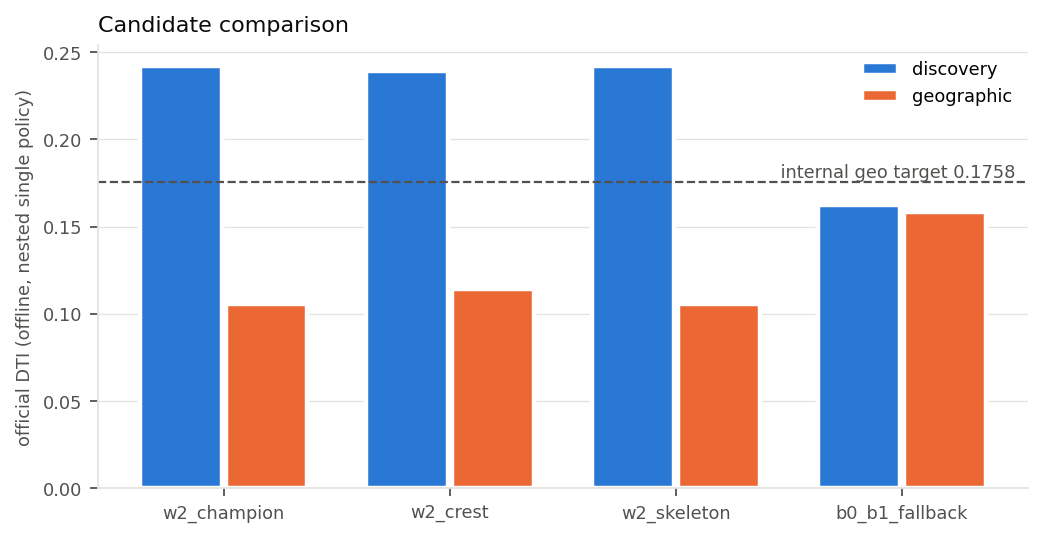

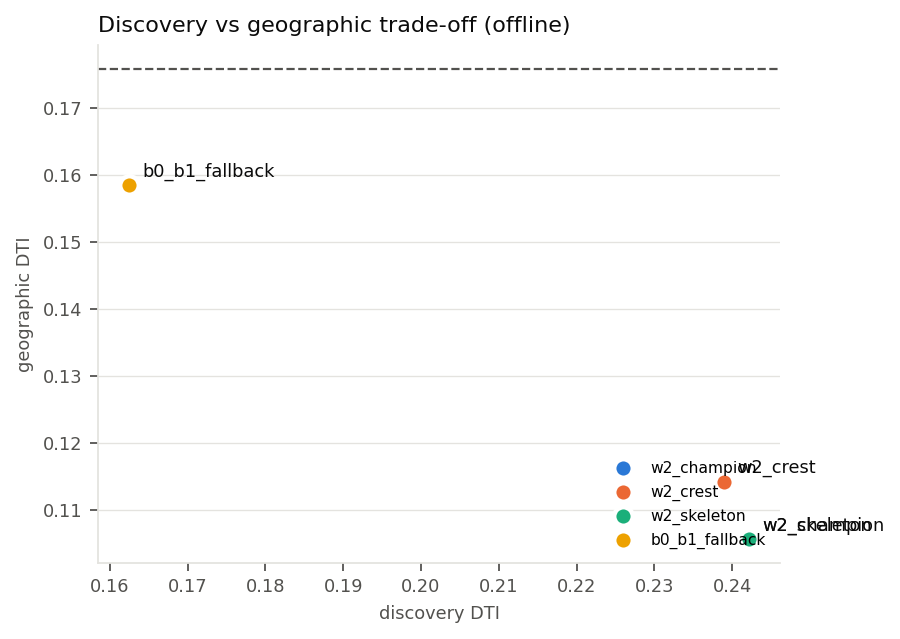

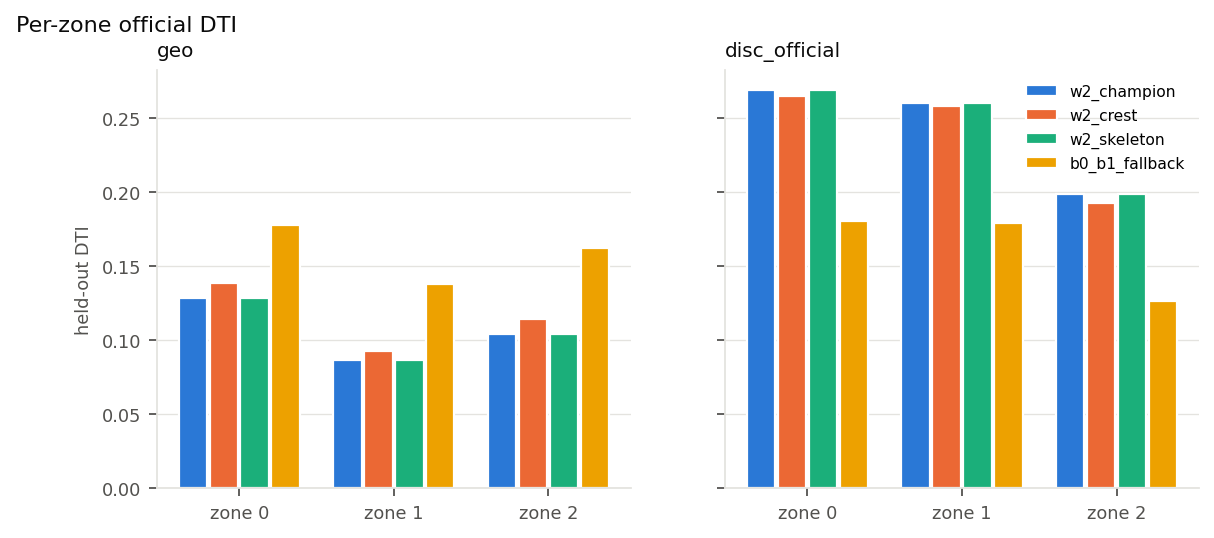

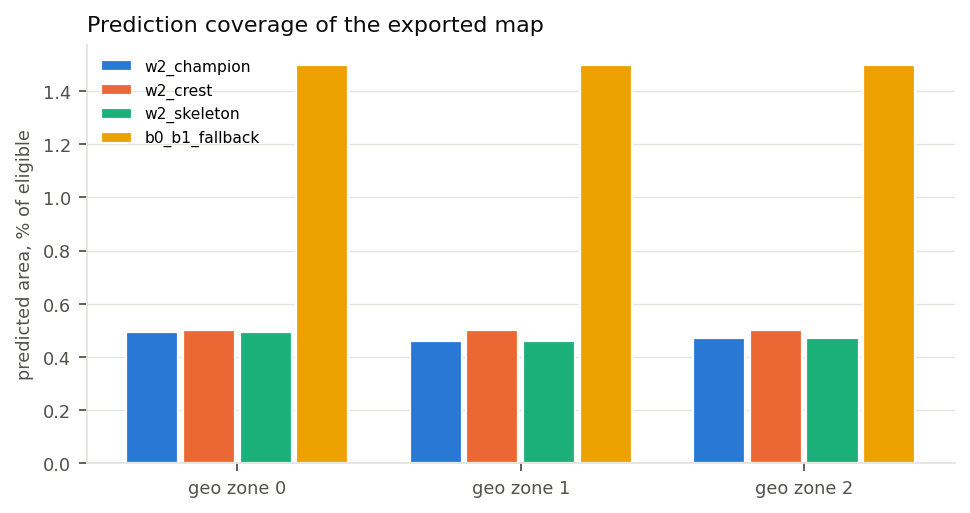

In [7]:
M = pd.read_csv(OUT / 'submissions/submission_manifest.csv', dtype={'recipe_id': str})
display(M[['candidate', 'status', 'upload_priority', 'recommendation_rank', 'file', 'TECHNICAL_VALIDATION',
           'EXPORT_PARITY', 'OFFICIAL_FORMAT', 'GEOGRAPHIC_TARGET_MET', 'disc_dti', 'geo_dti', 'duplicate_of',
           'first_reason']])
display(pd.read_csv(OUT / 'metrics/per_zone_scores.csv') if (OUT / 'metrics/per_zone_scores.csv').stat().st_size
        else 'no per-zone scores')
for fig in ('candidate_comparison', 'discovery_geographic_tradeoff', 'per_zone_dti', 'prediction_coverage'):
    p = OUT / 'figures' / f'{fig}.png'
    if p.exists():
        display(Image(filename=str(p)))

## 8 · Final execution report: which file to upload

In [8]:
display(Markdown((OUT / 'submissions/README_UPLOAD.md').read_text(encoding='utf-8')))
display(Markdown((OUT / 'reports/NEXT_ACTION.md').read_text(encoding='utf-8')))
print(open(OUT / 'submissions/submission_sha256.txt').read() or 'no READY file')

# Upload instructions (manual only)

Folder: `/content/drive/MyDrive/GEMS_2/outputs/leaderboard_focus/submission_factorysubmissions/`

## Upload this file first

**`submission_w2_champion_0a8692b2ab.tif`** (candidate `w2_champion`, recipe `0a8692b2ab`)

* sha256 `c634d321060f702720f37c82b5c692dcb84030d01af0f23ec130473273e3019b`
* offline nested DTI: discovery 0.242156, geographic 0.105687 (NOT leaderboard scores)
* geographic risk: single-policy geo DTI 0.105687 < internal target 0.1758 (exportable; not geographically robust)

## One meaningful alternative (optional, a later slot)

`submission_b0_b1_fallback_eedc29b045.tif` (candidate `b0_b1_fallback`): highest single-policy geo DTI 0.158416 > primary 0.105687 (disc 0.162482 vs 0.242156): its public score tells whether the leaderboard rewards geographic robustness or discovery strength

## Steps

1. Download the file from the Drive folder above.
2. Check it: `sha256sum <file>` must equal its line in `submission_sha256.txt`.
3. DrivenData -> GEMS competition -> Submissions -> upload the .tif (3 scored submissions per rolling 7 days: never spend two on DUPLICATE files).
4. Record the public score in the notebook's result-entry cell (`F.record_result`). Never re-select or tune on the public score.

## Every candidate

| candidate      | status           | upload_priority   | file                                     |   disc_dti |   geo_dti | GEOGRAPHIC_TARGET_MET   | first_reason                                                                                                                         |
|:---------------|:-----------------|:------------------|:-----------------------------------------|-----------:|----------:|:------------------------|:-------------------------------------------------------------------------------------------------------------------------------------|
| w2_champion    | READY_FOR_UPLOAD | PRIMARY           | submission_w2_champion_0a8692b2ab.tif    |   0.242156 |  0.105687 | False                   | GEOGRAPHIC_TARGET_MET False: single-policy geo DTI 0.105687 < internal target 0.1758 (geographic-risk warning; not a format problem) |
| w2_crest       | READY_FOR_UPLOAD | OPTIONAL          | submission_w2_crest_f653e4cb7a.tif       |   0.238882 |  0.114259 | False                   | GEOGRAPHIC_TARGET_MET False: single-policy geo DTI 0.114259 < internal target 0.1758 (geographic-risk warning; not a format problem) |
| w2_skeleton    | DUPLICATE        | DO_NOT_UPLOAD     |                                          |   0.242156 |  0.105687 | False                   | GEOGRAPHIC_TARGET_MET False: single-policy geo DTI 0.105687 < internal target 0.1758 (geographic-risk warning; not a format problem) |
| b0_b1_fallback | READY_FOR_UPLOAD | ALTERNATIVE       | submission_b0_b1_fallback_eedc29b045.tif |   0.162482 |  0.158416 | False                   | GEOGRAPHIC_TARGET_MET False: single-policy geo DTI 0.158416 < internal target 0.1758 (geographic-risk warning; not a format problem) |


# Next action

Upload `submission_w2_champion_0a8692b2ab.tif` by hand (see `submissions/README_UPLOAD.md`), then record its public score with `F.record_result`. Do not start new research before the public baseline exists.


c634d321060f702720f37c82b5c692dcb84030d01af0f23ec130473273e3019b  submission_w2_champion_0a8692b2ab.tif
f76cda530f128a70a8a21f2a4dfd0597a79fc3277a5e11fa4b87a61bdefb9bd8  submission_w2_crest_f653e4cb7a.tif
87bee141d3458232fadff614e2e0dd9ad73ab18fb98d8df36f7920755df6a92c  submission_b0_b1_fallback_eedc29b045.tif



## 9 · Manual leaderboard result (only after you uploaded a READY file by hand)

Fill `RESULT` and run. Refused when the candidate / recipe / checksum does not match a READY file, or the id / file was already recorded. Public scores are history only: they never change any offline result or selection.

In [9]:
RESULT = {
    'submission_id': '',          # DrivenData submission id
    'candidate': '',              # e.g. 'w2_champion'
    'recipe_id': '',              # from submission_manifest.csv
    'file_sha256': '',            # sha256sum of the uploaded file
    'public_score': None,
    'submission_date': '',        # YYYY-MM-DD
    'notes': '',
}
if RESULT['submission_id']:
    print(F.record_result(RESULT))
    display(pd.read_csv(OUT / 'leaderboard/leaderboard_results.csv'))
else:
    print('no result entered (fill RESULT after a manual upload)')

no result entered (fill RESULT after a manual upload)
